# Extraction des notes annexes financières – pipeline d'automatisation
**Question X/Y/Z** : un outil d'extraction automatisée des notes annexes (X) peut-il réduire le temps de traitement
et les erreurs de transcription (Y) par rapport à une recherche visuelle et une saisie manuelle dans Excel (Z) ?

**Workflow** : SOURCE → VALIDATE → CLEAN → TRANSFORM → EXTRACT → ÉCART DE CONTRÔLE → SEUIL → ALERTE → OUTPUT

Toute la logique est dans `pipeline.py` ; ce cahier exécute chaque étape et montre son résultat.

In [1]:
import pandas as pd
pd.set_option("display.max_columns", 30)
import pipeline as pl
DATA = "data/dataset_extraction_annexes_financieres.csv"

## 1. SOURCE – chargement et contrôle des colonnes

In [2]:
raw = pl.load_source(DATA)

[SOURCE] dataset_extraction_annexes_financieres.csv : 806 lignes, 27 colonnes
  id_ligne id_report id_entreprise       nom_entreprise    secteur    pays  \
0    L0001   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
1    L0002   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
2    L0003   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
3    L0004   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
4    L0005   RPT-001       ENT-001  Valmorel Industries  Industrie  France   

  referentiel_comptable exercice devise langue_rapport nb_pages_rapport  \
0                  IFRS     2025    EUR             FR              202   
1                  IFRS     2025    EUR             FR              202   
2                  IFRS     2025    EUR             FR              202   
3                  IFRS     2025    EUR             FR              202   
4                  IFRS     2025    EUR             FR              202   

  

## 2. VALIDATE – règles du Data Contract (aucune donnée modifiée)

In [3]:
report_before, details = pl.validate(raw)
report_before

,regle,description,gravite,nb_echecs,lignes_concernees
0,D1,Colonnes catégorielles dans les valeurs autori...,bloquant,0,
1,D2,valeur_reference présente et numérique,bloquant,0,
2,D3,page_note renseignée,avertissement,6,"L0002, L0043, L0050, L0137, L0591, L0702"
3,C1,Identités comptables respectées à l'arrondi près,bloquant,0,
4,C2a,Pas de doublon exact,corrigeable,12,"L0305, L0306, L0586, L0587, L0667, L0668, L068..."
5,C2b,Pas deux contenus différents pour la même clé ...,bloquant,0,
6,C3a,Secteur dans la liste de référence,corrigeable,6,"L0075, L0304, L0471, L0483, L0491, L0762"
7,C3b,Devise au format ISO,corrigeable,5,"L0016, L0024, L0287, L0359, L0564"
8,C3c,Date au format AAAA-MM-JJ,corrigeable,12,"L0049, L0065, L0122, L0193, L0265, L0428, L045..."
9,C4,Label cohérent : erreur_saisie=1 si et seuleme...,bloquant,0,


In [4]:
details.head(10)

,id_ligne,regle,gravite,raison
0,L0002,D3,avertissement,page_note vide
1,L0043,D3,avertissement,page_note vide
2,L0050,D3,avertissement,page_note vide
3,L0137,D3,avertissement,page_note vide
4,L0591,D3,avertissement,page_note vide
5,L0702,D3,avertissement,page_note vide
6,L0305,C2a,corrigeable,doublon exact d'une autre ligne
7,L0306,C2a,corrigeable,doublon exact d'une autre ligne
8,L0586,C2a,corrigeable,doublon exact d'une autre ligne
9,L0587,C2a,corrigeable,doublon exact d'une autre ligne


## 3. CLEAN – corrections explicables, quarantaine pour le reste

In [5]:
clean_df, quarantine, log, report_after, n_dup = pl.clean(raw)
print(f'Lignes propres : {len(clean_df)} | quarantaine : {len(quarantine)} | doublons supprimés : {n_dup}')
log

Lignes propres : 800 | quarantaine : 0 | doublons supprimés : 6


,action,colonne,nb_lignes,lignes,detail
0,standardisation du libellé,secteur,6,"L0075, L0304, L0471, L0483, L0491, L0762","{'Sante': 'Santé', 'Healthcare': 'Santé', 'ind..."
1,symbole remplacé par code ISO,devise,5,"L0016, L0024, L0287, L0359, L0564","{'€': 'EUR', '$': 'USD', '£': 'GBP'}"
2,date JJ/MM/AAAA convertie en AAAA-MM-JJ,date_saisie,12,"L0049, L0065, L0122, L0193, L0265, L0428, L045...",
3,doublon exact supprimé (1re occurrence conservée),toutes,6,"L0306, L0587, L0668, L0683, L0712, L0722",
4,alerte ajoutée (ligne conservée),alerte_temps,15,"L0001, L0030, L0192, L0200, L0236, L0276, L028...",temps manquant ou hors plage : exclu des indic...


In [6]:
report_before[['regle','description','nb_echecs']].merge(report_after[['regle','nb_echecs']], on='regle', suffixes=('_avant','_apres'))

,regle,description,nb_echecs_avant,nb_echecs_apres
0,D1,Colonnes catégorielles dans les valeurs autori...,0,0
1,D2,valeur_reference présente et numérique,0,0
2,D3,page_note renseignée,6,6
3,C1,Identités comptables respectées à l'arrondi près,0,0
4,C2a,Pas de doublon exact,12,0
5,C2b,Pas deux contenus différents pour la même clé ...,0,0
6,C3a,Secteur dans la liste de référence,6,0
7,C3b,Devise au format ISO,5,0
8,C3c,Date au format AAAA-MM-JJ,12,0
9,C4,Label cohérent : erreur_saisie=1 si et seuleme...,0,0


## 4. TRANSFORM – variables du projet et baseline manuelle

In [7]:
transformed, per_report, baseline = pl.transform(clean_df)
baseline

,mise_en_page_tableau,nb_rapports,temps_median_par_rapport_min,temps_moyen_par_rapport_min,taux_erreur_pct
0,imbriqué,9.0,36.82,37.22,12.78
1,multi-colonnes N/N-1,14.0,25.21,26.91,8.57
2,scanné/image,4.0,42.35,43.19,12.50
3,simple,13.0,23.50,24.67,1.54
4,TOTAL,40.0,27.47,30.13,7.62


## 5. EXTRACT – outil d'extraction v0
Le texte imprimé (`texte_brut_publie`) est converti en valeur : formats FR/EN, parenthèses = négatif, échelle en milliers.

In [8]:
for t, s, l in [("1 234,5", "millions", "FR"), ("(1,234.5)", "millions", "EN"), ("247 173", "milliers", "FR"), ("3,25 %", "pourcentage", "FR")]:
    print(f"{t:>12} -> {pl.parse_published_number(t, s, l)}")
df, runtime = pl.extract(transformed)
print(f"\nExactitude de l'outil : {100 - df['erreur_outil'].mean()*100:.1f} % en {runtime*1000:.1f} ms pour {len(df)} champs")

     1 234,5 -> 1234.5
   (1,234.5) -> -1234.5
     247 173 -> 247.173
      3,25 % -> 3.25

Exactitude de l'outil : 100.0 % en 2.7 ms pour 800 champs


## 6. ÉCART DE CONTRÔLE → SEUIL
Équivalent du « rendement journalier » du modèle du cours : écart (%) entre un total et la somme de ses composantes,
calculé sur les **valeurs extraites** (pas besoin de la vérité terrain).

In [9]:
gaps_manual = pl.control_gaps(df, 'valeur_saisie_manuelle', 'erreur_saisie', 'manuel')
gaps_manual.sort_values('ecart_pct', ascending=False).head(8)

,source,id_report,controle,champs_controles,total,somme_composantes,ecart,ecart_pct,unite_arrondi,numero_note,page_note,erreur_reelle
237,manuel,RPT-038,DETTE_LOCATIVE = courant + non courant,"DETTE_LOCATIVE, LOC_COURANT, LOC_NON_COURANT",-307.4,307.4,-614.8,200.0,0.100,22,117,True
231,manuel,RPT-032,DETTE_LOCATIVE = courant + non courant,"DETTE_LOCATIVE, LOC_COURANT, LOC_NON_COURANT",426.052,246.052,180.0,42.248364,0.001,23,122,True
117,manuel,RPT-038,DETTE_BRUTE = oblig. + bancaire + location,"DETTE_BRUTE, DETTE_OBLIGATAIRE, DETTE_BANCAIRE...",2077.8,1463.0,614.8,29.588988,0.100,22,117,True
186,manuel,RPT-027,DETTE_BRUTE = DETTE_NETTE + TRESORERIE,"DETTE_BRUTE, DETTE_NETTE, TRESORERIE",1944.5,2124.5,-180.0,9.256878,0.100,19,150,True
197,manuel,RPT-038,DETTE_BRUTE = DETTE_NETTE + TRESORERIE,"DETTE_BRUTE, DETTE_NETTE, TRESORERIE",2077.8,1897.8,180.0,8.663009,0.100,22,117,True
165,manuel,RPT-006,DETTE_BRUTE = DETTE_NETTE + TRESORERIE,"DETTE_BRUTE, DETTE_NETTE, TRESORERIE",2093.1,2249.5,-156.4,7.47217,0.100,26,166,True
16,manuel,RPT-017,CA_TOTAL = somme des segments,"CA_TOTAL, CA_SEG_1, CA_SEG_2, CA_SEG_3",33108.8,30857.9,2250.9,6.798495,0.100,6,163,True
176,manuel,RPT-017,DETTE_BRUTE = DETTE_NETTE + TRESORERIE,"DETTE_BRUTE, DETTE_NETTE, TRESORERIE",24682.1,23010.4,1671.7,6.772925,0.100,19,213,True


In [10]:
calibration = pl.calibrate(gaps_manual)
calibration

,seuil_pct,nb_alertes,vraies_alertes,fausses_alertes,erreurs_ratees,taux_detection_pct
0,4.0,30,30,0,33,47.6
1,2.0,38,38,0,25,60.3
2,1.0,45,45,0,18,71.4
3,0.5,46,46,0,17,73.0
4,0.1,53,53,0,10,84.1


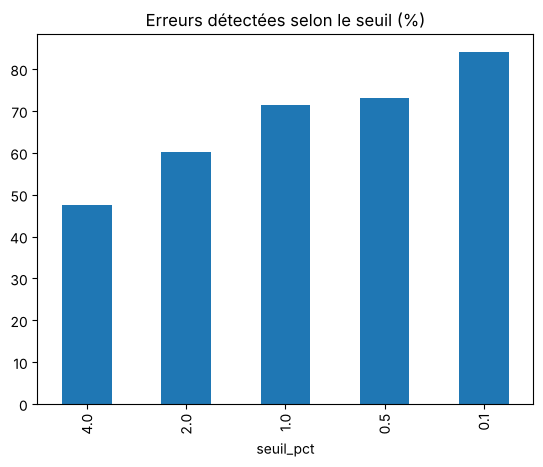

In [11]:
calibration.plot(x='seuil_pct', y='taux_detection_pct', kind='bar', legend=False, title='Erreurs détectées selon le seuil (%)');

## 7. ALERTE VISIBLE (seuil retenu : 0.1 %)

In [12]:
alerts = pl.build_alerts(gaps_manual, pl.THRESHOLD_PCT)
print(len(alerts), 'alertes')
alerts[['niveau','message','action']].head(10)

53 alertes


,niveau,message,action
0,ÉLEVÉ,RPT-038 – DETTE_LOCATIVE = courant + non coura...,Revérifier la note 22 (p. 117) : DETTE_LOCATIV...
1,ÉLEVÉ,RPT-032 – DETTE_LOCATIVE = courant + non coura...,Revérifier la note 23 (p. 122) : DETTE_LOCATIV...
2,ÉLEVÉ,RPT-038 – DETTE_BRUTE = oblig. + bancaire + lo...,"Revérifier la note 22 (p. 117) : DETTE_BRUTE, ..."
3,ÉLEVÉ,RPT-027 – DETTE_BRUTE = DETTE_NETTE + TRESORER...,"Revérifier la note 19 (p. 150) : DETTE_BRUTE, ..."
4,ÉLEVÉ,RPT-038 – DETTE_BRUTE = DETTE_NETTE + TRESORER...,"Revérifier la note 22 (p. 117) : DETTE_BRUTE, ..."
5,ÉLEVÉ,RPT-006 – DETTE_BRUTE = DETTE_NETTE + TRESORER...,"Revérifier la note 26 (p. 166) : DETTE_BRUTE, ..."
6,ÉLEVÉ,RPT-017 – CA_TOTAL = somme des segments : écar...,"Revérifier la note 6 (p. 163) : CA_TOTAL, CA_S..."
7,ÉLEVÉ,RPT-017 – DETTE_BRUTE = DETTE_NETTE + TRESORER...,"Revérifier la note 19 (p. 213) : DETTE_BRUTE, ..."
8,ÉLEVÉ,RPT-010 – DETTE_BRUTE = somme des échéances : ...,"Revérifier la note 19 (p. 149) : DETTE_BRUTE, ..."
9,ÉLEVÉ,RPT-031 – CA_TOTAL = somme des zones : écart d...,"Revérifier la note 6 (p. 140) : CA_TOTAL, CA_Z..."


## 8. Comparaison avec la baseline (Z)

In [13]:
gaps_tool = pl.control_gaps(df, 'valeur_extraite_outil', 'erreur_outil', 'outil')
pl.compare_with_baseline(df, per_report, alerts, pl.build_alerts(gaps_tool), runtime)

,scenario,temps_par_rapport_min,taux_erreur_residuel_pct
0,Saisie manuelle seule (baseline Z),30.133,7.625
1,Saisie manuelle + alerte,36.913,1.250
2,Outil d'extraction seul,0.000,0.000
3,Outil d'extraction + alerte (X),0.000,0.000


## 9. OUTPUT – tout le workflow en une commande

In [14]:
results = pl.run_pipeline(DATA, output_folder='outputs')

[SOURCE] dataset_extraction_annexes_financieres.csv : 806 lignes, 27 colonnes
  id_ligne id_report id_entreprise       nom_entreprise    secteur    pays  \
0    L0001   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
1    L0002   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
2    L0003   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
3    L0004   RPT-001       ENT-001  Valmorel Industries  Industrie  France   
4    L0005   RPT-001       ENT-001  Valmorel Industries  Industrie  France   

  referentiel_comptable exercice devise langue_rapport nb_pages_rapport  \
0                  IFRS     2025    EUR             FR              202   
1                  IFRS     2025    EUR             FR              202   
2                  IFRS     2025    EUR             FR              202   
3                  IFRS     2025    EUR             FR              202   
4                  IFRS     2025    EUR             FR              202   

  

[OUTPUT] 13 fichiers CSV écrits dans /home/claude/extraction-annexes-financieres/outputs

=========== RÉSUMÉ ===========
Lignes d'origine        : 806
Lignes propres          : 800
Lignes en quarantaine   : 0
Doublons supprimés      : 6
Échecs de validation    : 56 lignes / 56 échecs (avant nettoyage)
Lignes avec alerte      : 21 (conservées)

Baseline (saisie manuelle) :
mise_en_page_tableau  nb_rapports  temps_median_par_rapport_min  temps_moyen_par_rapport_min  taux_erreur_pct
            imbriqué          9.0                         36.82                        37.22            12.78
multi-colonnes N/N-1         14.0                         25.21                        26.91             8.57
        scanné/image          4.0                         42.35                        43.19            12.50
              simple         13.0                         23.50                        24.67             1.54
               TOTAL         40.0                         27.47            

## Limites
- Le texte publié est déjà propre : l'exactitude de 100 % de l'outil est triviale. La vraie difficulté (trouver le chiffre dans le PDF) reste à tester sur de vrais rapports.
- Zéro fausse alerte : les données synthétiques sont trop cohérentes.
- `LOC_INTERETS` et `TAUX_MOYEN_DETTE` ne sont couverts par aucune identité comptable.